<!-- d2l:prose id=transformer-block-md-1 fw=all -->

# The Transformer Block

Self-attention (that section) mixes information across sequence positions: each token's output is a weighted average of value vectors from the positions it attends to. On its own, however, an attention layer applies only linear projections ($W_Q, W_K, W_V, W_O$) around the weighted sum. Without a position-wise nonlinearity, residual connections, and normalization, stacking attention layers cannot build hierarchical per-token features or propagate signals reliably across dozens of layers.

The **Transformer block** [@Vaswani.Shazeer.Parmar.ea.2017] pairs multi-head attention with a position-wise **feed-forward network (FFN)**, wraps each sublayer in an additive **residual connection** [@He.Zhang.Ren.ea.2016], and stabilizes activations with **layer normalization** (the figure). Three design upgrades separate modern blocks from the original 2017 Transformer:

1. **Normalization placement:** Moving normalization from the residual stream itself (**post-norm**) to the input of each sublayer (**pre-norm**) preserves an unattenuated identity path across depth.
2. **Normalization form:** Replacing mean-centered `LayerNorm` with root-mean-square normalization (**`RMSNorm`**) and optional per-head **query--key normalization (`QK-Norm`)** bounds activations and attention logits with less memory-bandwidth overhead.
3. **Gated feed-forward networks:** Replacing the two-matrix ReLU/GELU MLP ($d_{\textrm{ff}} = 4d$) with a gated **`SwiGLU`** network ($d_{\textrm{ff}} \approx \frac{8}{3}d$) improves representation quality at the exact same $8d^2$ parameter and FLOP budget.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=transformer-block-md-2 fw=all -->

## Components of a Transformer Block

A Transformer block operates on a shared **residual stream** $\mathbf{X} \in \mathbb{R}^{B \times n \times d}$ (that section). Rather than overwriting $\mathbf{X}$, two consecutive sublayers read from the stream, compute an update, and add their result back:

- **Multi-head attention (token mixing)** is the only place where sequence positions interact: each token queries the sequence (that section) and adds the retrieved context vector to its stream.
- **Position-wise feed-forward network (channel mixing)** applies the same MLP independently to each token vector $\mathbf{x}_i \in \mathbb{R}^d$, transforming the features accumulated by attention. Roughly two-thirds of a dense block's parameters reside in the FFN.

In the **pre-norm** arrangement used by modern Transformers (the figure), each sublayer normalizes its own input before computing its update:

$$
\begin{aligned}
\mathbf{H} &= \mathbf{X} + \textrm{Attn}\!\bigl(\textrm{Norm}(\mathbf{X})\bigr), \\
\mathbf{Y} &= \mathbf{H} + \textrm{FFN}\!\bigl(\textrm{Norm}(\mathbf{H})\bigr).
\end{aligned}
$$

![The transformer block: attention and a position-wise FFN read from the residual stream and add their results back. Left, the 2017 arrangement: normalization sits on the stream itself, after each addition. Right, the modern arrangement: normalization moves onto each branch, and the stream runs uninterrupted from input to output.](../img/mdl-transformers-block-anatomy.svg)

## Normalization

### Pre-Norm vs. Post-Norm

The original 2017 Transformer [@Vaswani.Shazeer.Parmar.ea.2017] and BERT [@Devlin.Chang.Lee.ea.2018] used **post-norm**, placing normalization *on the residual stream itself* after each addition:

$$
\begin{aligned}
\mathbf{H} &= \textrm{Norm}\!\bigl(\mathbf{X} + \textrm{Attn}(\mathbf{X})\bigr), \\
\mathbf{Y} &= \textrm{Norm}\!\bigl(\mathbf{H} + \textrm{FFN}(\mathbf{H})\bigr).
\end{aligned}
$$

Why did modern architectures switch from the equation to the equation? We can see the difference directly at initialization without training a single step, using a minimal block `MiniBlock` whose flag `pre_norm` switches between the two arrangements:

In [2]:
class MiniBlock(nn.Module):
    """Attention + MLP on a residual stream; norm placement as a flag."""
    def __init__(self, num_hiddens, pre_norm):
        super().__init__()
        self.pre_norm = pre_norm
        self.attention = d2l.MultiHeadAttention(num_hiddens, 4)
        self.W_1 = nn.Linear(num_hiddens, 4 * num_hiddens)
        self.W_2 = nn.Linear(4 * num_hiddens, num_hiddens)
        self.norm1 = nn.LayerNorm(num_hiddens, eps=1e-5)
        self.norm2 = nn.LayerNorm(num_hiddens, eps=1e-5)

    def ffn(self, X):  # exact GELU
        return self.W_2(F.gelu(self.W_1(X)))

    def forward(self, X):
        if self.pre_norm:
            Y = self.norm1(X)
            X = X + self.attention(Y, Y, Y)
            return X + self.ffn(self.norm2(X))
        X = self.norm1(X + self.attention(X, X, X))
        return self.norm2(X + self.ffn(X))

<!-- d2l:prose id=transformer-block-md-3 fw=all -->

### Signal Propagation and Token Collapse at Initialization

Consider passing a batch of random unit-variance token vectors $\mathbf{X}^{(0)} \in \mathbb{R}^{B \times n \times d}$ through $L = 32$ freshly initialized blocks. The function `signal_stats` below draws every weight matrix of the stack afresh, with Xavier initialization as in the 2017 Transformer, or with $\mathcal{N}(0, \textrm{std}^2)$ entries if `std` is given. At each block $\ell \in \{1, \dots, L\}$, we track three quantities:

1. **Stream standard deviation** across all entries of $\mathbf{X}^{(\ell)}$;
2. **Token spread**, measured as the standard deviation across the $n$ sequence positions (which vanishes if all $n$ tokens collapse onto the same vector); and
3. **Query gradient norm** $\|\partial \mathcal{L} / \partial W_q^{(\ell)}\|_F$ flowing back from a unit scalar loss at the top of the stack:

In [3]:
def signal_stats(pre_norm, std=None, num_blks=32, num_hiddens=256):
    """Token spread, stream RMS, and gradient norms of a fresh stack whose
    weight matrices are Xavier, or N(0, std^2) if std is given."""
    blks = nn.ModuleList([MiniBlock(num_hiddens, pre_norm)
                          for _ in range(num_blks)])
    init = (nn.init.xavier_uniform_ if std is None  # the 2017 initialization
            else lambda W: nn.init.normal_(W, std=std))
    for p in blks.parameters():
        if p.ndim == 2:
            init(p)
    norm = torch.linalg.vector_norm
    H = torch.randn(2, 64, num_hiddens)
    spread, rms = [], []
    for blk in blks:
        H = blk(H)
        spread.append(norm(H - H.mean(1, keepdim=True)) / norm(H))
        rms.append(H.pow(2).mean().sqrt())
    (H * torch.randn_like(H)).mean().backward()  # generic readout loss
    grad_q = [norm(blk.attention.W_q.weight.grad) for blk in blks]
    proj = {n: norm(getattr(blks[-1].attention, n).weight.grad).item()
            for n in ('W_q', 'W_k', 'W_v', 'W_o')}
    return {'spread': torch.stack(spread).tolist(),
            'rms': torch.stack(rms).tolist(),
            'grad_q': torch.stack(grad_q).tolist(), 'proj': proj}

<!-- d2l:prose id=transformer-block-md-4 fw=all -->

Why does post-norm lose token diversity across depth? Split each token into the part that all tokens share and the part that is its own, $\mathbf{x}_i = \boldsymbol{\mu} + \boldsymbol{\delta}_i$, where $\boldsymbol{\mu} = \frac{1}{n}\sum_j \mathbf{x}_j$ is the mean over the $n$ positions (the figure). At initialization the attention weights are close to uniform, so every token receives nearly the same update $\mathbf{u} \approx \mathbf{W}_o\mathbf{W}_v\boldsymbol{\mu}$: the deviations average out and only the mean is passed on. Each of the two projections multiplies the squared length of its input by $g^2 = d\sigma^2$, where $\sigma^2$ is the variance of a weight entry, and the random vector $\mathbf{u}$ is nearly orthogonal to $\boldsymbol{\mu}$. The energy of the shared part therefore grows by the factor $1 + g^4$, while the deviations stay as they were. The normalization that follows cannot repair this. It rescales every token by the same factor, which restores the length of the stream but not the balance between the mean and the deviations.

![Token collapse in one post-norm block. Each token splits into the shared mean $\boldsymbol{\mu}$ and its own deviation $\boldsymbol{\delta}_i$. Nearly uniform attention adds the same update $\mathbf{u} \approx \mathbf{W}_o\mathbf{W}_v\boldsymbol{\mu}$ to every token, so only the mean grows. The normalization that follows rescales all tokens by one factor, which shrinks the deviations. Drawn for Xavier initialization ($g = 1$), where $\mathbf{u}$ is as long as $\boldsymbol{\mu}$ and the factor is $1/\sqrt{2}$.](../img/mdl-transformers-token-collapse.svg)

Let $\rho = n\|\boldsymbol{\mu}\|^2 / \sum_i \|\boldsymbol{\delta}_i\|^2$ be the ratio of shared to token-specific energy. Each block multiplies $\rho$ by $1 + g^4$. The token spread, the fraction of the stream's norm that lies in the deviations, is $s = (1 + \rho)^{-1/2}$, and $n$ independent random tokens start at $\rho_0 = 1/(n-1)$. After $k$ blocks we thus expect

$$
s_k \approx \Bigl(1 + \frac{(1 + g^4)^k}{n - 1}\Bigr)^{-1/2}.
$$

Once the mean dominates, the spread shrinks by the factor $1/\sqrt{1 + g^4}$ per block, which is $1/\sqrt{2}$ under Xavier initialization ($g = 1$). Note that the FFN does not appear in the equation. It acts on each token separately and cannot tell the mean from the deviations, so it changes their ratio very little (Exercise 5).

Under pre-norm (the equation), the residual stream is never divided by a normalization denominator: unrolling $L$ blocks gives a direct sum $\mathbf{X}^{(L)} = \mathbf{X}^{(0)} + \sum_{\ell=1}^{2L} \mathbf{U}^{(\ell)}$. Because $2L$ independent sublayer outputs add variance to the stream, the unscaled pre-norm stream RMS grows with depth as $\sqrt{1 + 2\ell\sigma^2}$ (to keep the total variance deposited by all $2L$ sublayers $O(1)$ at any depth $L$, GPT-2 [@Radford.Wu.Child.ea.2019] scales the initialization standard deviation of each block's residual output projections `W_o` and `W_2` by $1/\sqrt{2L}$, as we implement in that section and test in Exercise 4). Meanwhile, in post-norm, BERT [@Devlin.Chang.Lee.ea.2018] slows down the collapse the equation by initializing all linear weights with a smaller standard deviation $\sigma = 0.02$ (so $g^2 \approx 0.10$ and $g^4 \approx 0.01$ at $d = 256$). Let us compare these three configurations (`post-norm`, `pre-norm`, and `post-norm, std 0.02`) across 32 blocks:

In [4]:
arms = {'post-norm': (False, None), 'pre-norm': (True, None),
        'post-norm, std 0.02': (False, 0.02)}
stats, predicted = {}, {}
at = lambda xs, ks=(8, 16, 32): ' '.join(f'{xs[k - 1]:.1e}' for k in ks)
for name, (pre_norm, std) in arms.items():
    stats[name] = s = signal_stats(pre_norm, std)
    print(f'{name}: stream RMS at k=32 {s["rms"][-1]:.2f}')
    print(f'  token spread at k=8,16,32: {at(s["spread"])}')
    if not pre_norm:  # rho_0 = 1/63 for 64 random tokens; Xavier: g = 1
        g2 = 1 if std is None else 256 * std ** 2
        predicted[name] = [(1 + (1 + g2 ** 2) ** k / 63) ** -0.5
                           for k in range(1, 33)]
        print(f'  predicted:                 {at(predicted[name])}')
    print(f'  W_q grad norm at k=1,8,16,32: {at(s["grad_q"], (1, 8, 16, 32))}')
    print('  grad norms at k=32: ' + '  '.join(
        f'{n} {g:.1e}' for n, g in s['proj'].items()))

post-norm: stream RMS at k=32 1.00
  token spread at k=8,16,32: 3.1e-01 2.5e-02 1.2e-04
  predicted:                 4.4e-01 3.1e-02 1.2e-04
  W_q grad norm at k=1,8,16,32: 1.3e-02 2.3e-03 1.8e-05 4.1e-09
  grad norms at k=32: W_q 4.1e-09  W_k 4.1e-09  W_v 6.4e-02  W_o 5.9e-02


pre-norm: stream RMS at k=32 5.12
  token spread at k=8,16,32: 6.8e-01 5.2e-01 3.8e-01
  W_q grad norm at k=1,8,16,32: 6.2e-02 2.0e-02 7.9e-03 2.3e-03
  grad norms at k=32: W_q 2.3e-03  W_k 2.3e-03  W_v 8.1e-02  W_o 8.4e-02


post-norm, std 0.02: stream RMS at k=32 1.00
  token spread at k=8,16,32: 9.9e-01 9.8e-01 9.7e-01
  predicted:                 9.9e-01 9.9e-01 9.9e-01
  W_q grad norm at k=1,8,16,32: 4.1e-04 4.0e-04 4.0e-04 4.0e-04
  grad norms at k=32: W_q 4.0e-04  W_k 4.1e-04  W_v 6.9e-03  W_o 7.1e-03


<!-- d2l:prose id=transformer-block-md-5 fw=all -->

We plot the measured token spread across blocks $k = 1, \ldots, 32$ next to the prediction the equation for the two post-norm arms (dotted, with $n = 64$):

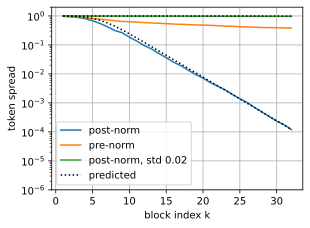

In [5]:
d2l.plot(list(range(1, 33)), [s['spread'] for s in stats.values()]
         + list(predicted.values()), 'block index k', 'token spread',
         legend=list(arms) + ['predicted'], yscale='log', ylim=(1e-6, 2),
         fmts=('C0-', 'C1-', 'C2-', 'k:', 'k:'), figsize=(4.5, 3.3),
         legend_loc='lower left')

<!-- d2l:prose id=transformer-block-md-6 fw=all -->

Under standard Xavier post-norm (`post-norm`), token spread collapses to nearly zero ($\sim 10^{-4}$) by block 32, closely tracking the prediction the equation: all tokens in the sequence have been squeezed into nearly identical vectors. The measured curve runs slightly below the dotted one, which is the small contribution of the FFN. Shrinking the post-norm initialization (`post-norm, std 0.02`) slows the per-block contraction enough to preserve token spread across 32 blocks. Pre-norm (`pre-norm`) is not immune, since its attention sublayers also add to the shared mean. But its stream grows with depth, so each update weighs less than the one before, and the spread decays slowly: more than a third of it is left after 32 blocks, even at Xavier scale (the stream RMS meanwhile grows as $\sqrt{L}$ unless paired with $1/\sqrt{2L}$ output-projection scaling; Exercise 4).

### Gradients at Initialization

Token collapse is a property of the forward pass, but it also decides which weights can learn. We plot the gradient norm $\|\partial \mathcal{L} / \partial W_q^{(\ell)}\|_F$ of the query projection across block index $\ell \in \{1, \dots, 32\}$:

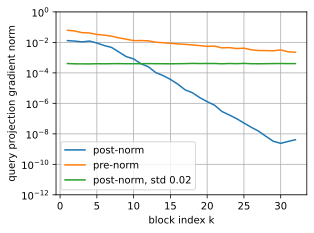

In [6]:
d2l.plot(list(range(1, 33)), [s['grad_q'] for s in stats.values()],
         'block index k', 'query projection gradient norm',
         legend=list(arms), yscale='log', ylim=(1e-12, 1),
         fmts=('C0-', 'C1-', 'C2-'), figsize=(4.5, 3.3),
         legend_loc='lower left')

<!-- d2l:prose id=transformer-block-md-7 fw=all -->

In `post-norm`, the query gradient is largest at block 1, around $10^{-2}$, and falls to about $10^{-9}$ at block 32. This is the reverse of the vanishing gradients of a deep MLP, where the layers farthest from the loss receive the least. The gradient is not lost on the way back. It is lost because of what the deep blocks see on the way forward: once the tokens entering a block nearly coincide, every key receives the same score and every value is the same, so moving a query changes nothing in the output. The query gradient accordingly shrinks with the square of the token spread, one factor because the scores differ only through the deviations $\boldsymbol{\delta}_i$ and a second because the values do, and the key gradient shrinks with it. The other weights are not affected. At block 32 the gradients of `W_v` and `W_o` have the same order of magnitude in `post-norm` and `pre-norm` (the last line printed for each arm above).

In `pre-norm`, the identity term $I$ in $\partial \mathbf{X}^{(L)} / \partial \mathbf{X}^{(\ell)} = I + \cdots$ carries the gradient from the loss to every block. Its query gradient is not uniform either: it declines by a factor of about 30 over the stack, as the token spread slowly decays. But it stays above $10^{-3}$ where post-norm loses more than six orders of magnitude. @xiong2020layer analyze a different imbalance of post-norm Transformers at initialization, namely large gradients for the parameters near the output, and show that this is why post-norm training depends on a learning-rate warmup while pre-norm trains without one.

### RMSNorm

Standard LayerNorm (that section) centers each token vector $\mathbf{x} \in \mathbb{R}^d$ by its mean $\mu = \frac{1}{d}\sum_j x_j$, scales by its standard deviation, and applies learned gain $\boldsymbol{\gamma}$ and bias $\boldsymbol{\beta}$. @Zhang.Sennrich.2019 showed that mean-centering and the additive bias contribute little to training stability: what matters is normalizing the root-mean-square magnitude. Dropping $\mu$ and $\boldsymbol{\beta}$ yields **RMSNorm**:

$$
\begin{aligned}
\textrm{RMSNorm}(\mathbf{x}) &= \frac{\mathbf{x}}{\textrm{RMS}(\mathbf{x})} \odot \boldsymbol{\gamma}, \\
\textrm{RMS}(\mathbf{x}) &= \sqrt{\frac{1}{d}\sum_{j=1}^{d} x_j^2 + \epsilon},
\end{aligned}
$$

where $\boldsymbol{\gamma} \in \mathbb{R}^d$ is initialized to ones and $\epsilon = 10^{-5}$. Because RMSNorm computes only a single mean-of-squares reduction $\frac{1}{d}\sum_j x_j^2$ per token instead of both mean and variance, it performs fewer memory reductions while matching LayerNorm accuracy:

In [7]:
def rms_norm(X, weight=1, eps=1e-5):
    return X / torch.sqrt((X * X).mean(-1, keepdim=True) + eps) * weight

x = torch.tensor([1.0, 2.0, 3.0, 6.0])
rmsnorm, layernorm = nn.RMSNorm(4, eps=1e-5), nn.LayerNorm(4, eps=1e-5)
show = lambda v: ' '.join(f'{a:5.2f}' for a in v.tolist())
print(f'ours vs. nn.RMSNorm: max deviation '
      f'{(rms_norm(x) - rmsnorm(x)).abs().max():.1e}')
for name, v in (('x', x), ('3x', 3 * x), ('x + 10', x + 10)):
    print(f'{name:>6}: RMSNorm {show(rms_norm(v))} | '
          f'LayerNorm {show(layernorm(v))}')

ours vs. nn.RMSNorm: max deviation 0.0e+00
     x: RMSNorm  0.28  0.57  0.85  1.70 | LayerNorm -1.07 -0.53  0.00  1.60
    3x: RMSNorm  0.28  0.57  0.85  1.70 | LayerNorm -1.07 -0.53  0.00  1.60
x + 10: RMSNorm  0.84  0.91  0.99  1.22 | LayerNorm -1.07 -0.53  0.00  1.60


<!-- d2l:prose id=transformer-block-md-8 fw=all -->

### Query--Key Normalization (QK-Norm)

Pre-norm normalizes the input $\mathbf{X}$ entering the attention sublayer, but inside attention the queries $\mathbf{Q} = \textrm{Norm}(\mathbf{X})\mathbf{W}_q$ and keys $\mathbf{K} = \textrm{Norm}(\mathbf{X})\mathbf{W}_k$ are multiplied by learned projection matrices $\mathbf{W}_q, \mathbf{W}_k$. If the singular values of $\mathbf{W}_q$ and $\mathbf{W}_k$ grow during training, the scaled dot-product logits $\mathbf{q}_i^\top \mathbf{k}_j / \sqrt{d_h}$ grow quadratically with weight scale, pushing softmax into one-hot saturation where its gradients vanish [@Henry.Dachapally.Pawar.ea.2020; @Dehghani.Djolonga.Mustafa.ea.2023].

**QK-Norm** applies per-head `RMSNorm` of width $d_h$ to $\mathbf{Q}$ and $\mathbf{K}$ immediately before computing attention scores. By Cauchy--Schwarz, two vectors of unit RMS have dot product bounded by $d_h$, so the scaled logit $\mathbf{q}_i^\top \mathbf{k}_j / \sqrt{d_h}$ is bounded in magnitude by $\sqrt{d_h}$ (and has unit variance for random directions) regardless of how large $\|\mathbf{W}_q\|$ and $\|\mathbf{W}_k\|$ grow:

In [8]:
def logit_stats(Q, K):
    """Std of the scaled logits; mean entropy of each query's weights."""
    S = Q @ K.T / math.sqrt(Q.shape[-1])
    entropy = -(F.softmax(S, -1) * F.log_softmax(S, -1)).sum(-1).mean()
    return S.std(), entropy

d, d_h = 256, 64
X = torch.randn(64, d)                                # 64 random tokens
W_q, W_k = torch.randn(2, d, d_h) / math.sqrt(d)      # one head
for lam in (1, 4, 16):
    Q, K = X @ (lam * W_q), X @ (lam * W_k)
    s, h = logit_stats(Q, K)
    s_n, h_n = logit_stats(rms_norm(Q), rms_norm(K))
    print(f'lambda {lam:2d}: logit std {s:5.1f}, entropy {h:.2f} | '
          f'QK-norm: logit std {s_n:.2f}, entropy {h_n:.2f}')

lambda  1: logit std   1.0, entropy 3.69 | QK-norm: logit std 1.01, entropy 3.69
lambda  4: logit std  16.3, entropy 0.25 | QK-norm: logit std 1.01, entropy 3.69
lambda 16: logit std 261.4, entropy 0.01 | QK-norm: logit std 1.01, entropy 3.69


<!-- d2l:prose id=transformer-block-md-9 fw=all -->

When $Q$ and $K$ are scaled by $\lambda = 4\times$ and $\lambda = 16\times$ without QK-Norm, the logit standard deviation jumps quadratically ($\approx 16$ and $\approx 256$) and softmax entropy collapses toward zero; with `rms_norm` applied to $Q$ and $K$, logit spread and attention entropy remain completely invariant to the weight scale.

## The Feed-Forward Network: From GELU to SwiGLU

The original Transformer feed-forward network is a two-layer MLP that expands channel width from $d$ to $d_{\textrm{ff}} = 4d$, applies an elementwise activation ($\textrm{ReLU}$ in @Vaswani.Shazeer.Parmar.ea.2017, $\textrm{GELU}$ in GPT-2 and BERT), and projects back to $d$:

$$
\begin{aligned}
\textrm{FFN}_{\textrm{GELU}}(\mathbf{x}) &= \textrm{GELU}(\mathbf{x}\mathbf{W}_1 + \mathbf{b}_1)\mathbf{W}_2 + \mathbf{b}_2, \\
\mathbf{W}_1 &\in \mathbb{R}^{d \times 4d}, \qquad \mathbf{W}_2 \in \mathbb{R}^{4d \times d},
\end{aligned}
$$

using $2 \cdot d \cdot 4d = 8d^2$ weight parameters.

Following @Dauphin.Fan.Auli.ea.2017 and @Shazeer.2020, modern Transformers replace the equation with a bias-free **SwiGLU** gated linear unit, which takes the elementwise product of a $\textrm{SiLU}$-activated gate projection $\mathbf{x}\mathbf{W}_g$ ($\textrm{SiLU}(z) = z \sigma(z)$) and a linear up-projection $\mathbf{x}\mathbf{W}_1$ before projecting back down to $\mathbb{R}^d$ with $\mathbf{W}_2$:

$$
\textrm{FFN}_{\textrm{SwiGLU}}(\mathbf{x}) = \bigl(\textrm{SiLU}(\mathbf{x}\mathbf{W}_g) \odot (\mathbf{x}\mathbf{W}_1)\bigr)\mathbf{W}_2.
$$

Because `SwiGLU` uses *three* matrices of shape $d \times d_{\textrm{ff}}$ ($\mathbf{W}_g, \mathbf{W}_1$) and $d_{\textrm{ff}} \times d$ ($\mathbf{W}_2$), setting $d_{\textrm{ff}} = \operatorname{round}(\frac{8}{3}d)$ gives $3 d d_{\textrm{ff}} \approx 8d^2$, matching both the parameter count and the FLOP count of the $4d$ GELU MLP:

In [9]:
class FeedForward(nn.Module):
    """Position-wise FFN: GELU MLP or SwiGLU at matched parameter count."""
    def __init__(self, num_hiddens, act='swiglu', bias=False):
        super().__init__()
        assert act in ('swiglu', 'gelu'), f'unknown act: {act!r}'
        self.act = act
        if act == 'gelu':
            width = 4 * num_hiddens
        else:  # 'swiglu': three matrices; width 8d/3 matches the MLP budget
            width = round(8 * num_hiddens / 3)
            self.W_g = nn.Linear(num_hiddens, width, bias=bias)
        self.W_1 = nn.Linear(num_hiddens, width, bias=bias)
        self.W_2 = nn.Linear(width, num_hiddens, bias=bias)

    def forward(self, X):
        if self.act == 'gelu':  # The tanh approximation, as in GPT-2
            return self.W_2(F.gelu(self.W_1(X), approximate='tanh'))
        return self.W_2(F.silu(self.W_g(X)) * self.W_1(X))

<!-- d2l:prose id=transformer-block-md-10 fw=all -->

## A Configurable `TransformerBlock`

We now assemble `TransformerBlock` combining pre-norm or post-norm placement (`pre_norm`), `RMSNorm` or `LayerNorm` (`norm`), `SwiGLU` or `GELU` FFN (`act`), bias toggle (`bias`), and pluggable `attn_factory` and `ffn_factory` hooks (which allow upcoming sections to drop in causal RoPE attention in that section or Mixture-of-Experts layers in that section without rewriting the block):

In [10]:
class TransformerBlock(nn.Module):
    """Configurable transformer block: attention + FFN on a residual
    stream."""
    def __init__(self, num_hiddens, num_heads, *, dropout=0, norm='rms',
                 act='swiglu', pre_norm=True, bias=False, attn_factory=None,
                 ffn_factory=None):
        super().__init__()
        assert norm in ('rms', 'layer'), f'unknown norm: {norm!r}'
        assert num_hiddens % num_heads == 0
        self.pre_norm = pre_norm
        make_norm = nn.RMSNorm if norm == 'rms' else nn.LayerNorm
        self.norm1 = make_norm(num_hiddens, eps=1e-5)
        self.norm2 = make_norm(num_hiddens, eps=1e-5)
        self.attention = (d2l.MultiHeadAttention(num_hiddens, num_heads,
                                                 dropout, bias=bias)
                          if attn_factory is None else attn_factory())
        self.ffn = (FeedForward(num_hiddens, act, bias=bias)
                    if ffn_factory is None else ffn_factory())
        self.dropout = nn.Dropout(dropout)

    def forward(self, X, mask=None, **attn_args):
        # attn_args go on to the attention, e.g. the RoPE tables of d2l.GPT
        if self.pre_norm:
            Y = self.norm1(X)
            X = X + self.dropout(self.attention(Y, Y, Y, mask, **attn_args))
            return X + self.dropout(self.ffn(self.norm2(X)))
        X = self.norm1(X + self.dropout(self.attention(X, X, X, mask,
                                                       **attn_args)))
        return self.norm2(X + self.dropout(self.ffn(X)))

<!-- d2l:prose id=transformer-block-md-11 fw=all -->

### Parameter Count

Comparing the default modern block (`RMSNorm`, `SwiGLU`, `bias=False`) against the 2017/GPT-2 variants (`GELU`, `LayerNorm`, `bias=True`) at $d = 256, H = 8$ confirms that every configuration holds $\approx 12 d^2 = 786{,}432$ parameters ($4d^2$ in attention and $8d^2$ in the FFN):

In [11]:
blocks = {'default': TransformerBlock(256, 8),
          'GELU': TransformerBlock(256, 8, act='gelu'),
          '2017': TransformerBlock(256, 8, norm='layer', act='gelu',
                                   pre_norm=False, bias=True)}
for name, blk in blocks.items():
    attn, ffn, total = (d2l.num_params(m)
                        for m in (blk.attention, blk.ffn, blk))
    print(f'{name:>7}: attention {attn:,}, FFN {ffn:,}, total {total:,} '
          f'= {total / 256 ** 2:.2f} d^2')

default: attention 262,144, FFN 524,544, total 787,200 = 12.01 d^2
   GELU: attention 262,144, FFN 524,288, total 786,944 = 12.01 d^2
   2017: attention 263,168, FFN 525,568, total 789,760 = 12.05 d^2


<!-- d2l:prose id=transformer-block-md-12 fw=all -->

## Summary

A **Transformer block** separates **token mixing** (multi-head attention across sequence positions) from **channel mixing** (a position-wise feed-forward network across the $d$ features), adding both updates to a shared residual stream. **Pre-norm** (the equation) normalizes only the input to each sublayer and leaves the residual stream an uninterrupted identity path, whereas **post-norm** (the equation) normalizes the stream itself; at Xavier scale a deep post-norm stack loses inter-token differences exponentially fast (the equation) and starves the query and key gradients of its upper blocks, whereas scaling each block's residual output projections (`W_o` and `W_2`) by $1/\sqrt{2L}$ keeps pre-norm stream variance $O(1)$ across arbitrary depth $L$. Modern blocks pair **RMSNorm** (the equation), which drops LayerNorm's mean subtraction and additive bias, with per-head **QK-Norm** to bound attention logits via Cauchy--Schwarz regardless of projection weight growth. Finally, **SwiGLU** (the equation) replaces the two-matrix $4d$ feed-forward network with a three-matrix gated product at width $d_{\textrm{ff}} = \operatorname{round}(\frac{8}{3}d)$, matching the $8d^2$ parameter and FLOP budget of a standard FFN.

## Exercises

1. **Scale invariance of RMSNorm and its Jacobian.** Let $\mathbf{y} = \textrm{RMSNorm}(\mathbf{x})$ act as in the equation with $\epsilon = 0$ and $\boldsymbol{\gamma} = \mathbf{1}$.
   1. Show that $\textrm{RMSNorm}(c\mathbf{x}) = \textrm{RMSNorm}(\mathbf{x})$ for every scalar $c > 0$.
   2. Differentiate $\mathbf{y} = \sqrt{d}\, \mathbf{x} / \|\mathbf{x}\|_2$ to show that the Jacobian is $J(\mathbf{x}) = \frac{\sqrt{d}}{\|\mathbf{x}\|_2}\bigl(\mathbf{I} - \frac{\mathbf{x}\mathbf{x}^\top}{\|\mathbf{x}\|_2^2}\bigr)$, and verify that $J(\mathbf{x})\mathbf{x} = \mathbf{0}$. Why must any radial perturbation parallel to $\mathbf{x}$ lie in the null space of $J(\mathbf{x})$?

2. **Unrolled residual stream and gradient identity path.** Number the $2L$ sublayers of an $L$-block pre-norm stack as $f_1, f_2, \dots, f_{2L}$, where odd indices are attention sublayers and even indices are FFN sublayers.
   1. Unroll the equation to express $\mathbf{X}^{(L)}$ explicitly as $\mathbf{X}^{(0)} + \sum_{m=1}^{2L} f_m(\textrm{Norm}(\mathbf{X}^{(m-1)/2}))$.
   2. Apply the chain rule to write $\partial \mathbf{X}^{(L)} / \partial \mathbf{X}^{(0)}$ as a product of $2L$ Jacobians, expand the leading terms, and contrast the resulting identity term $\mathbf{I}$ with the post-norm product where every factor is premultiplied by $J_{\textrm{Norm}}$.

3. **QK-Norm inside `TransformerBlock`.** Write an `attn_factory` that wraps `d2l.MultiHeadAttention` and applies an RMSNorm of width `d // h` to queries and keys per head before computing attention scores. Verify on a 16-block stack with projection weights multiplied by $4\times$ (or $16\times$) that attention entropy remains bounded away from zero.

4. **Stream variance budget across depth.** In the pre-norm arrangement, every sublayer adds an update to the residual stream. Run `signal_stats(pre_norm=True, std=0.02 / math.sqrt(2 * L), num_blks=L)` for $L \in \{8, 16, 32, 64\}$ and compare against unscaled `std=None`. Verify that the final stream standard deviation at block $L$ grows as $\sqrt{L}$ without scaling but remains near a constant independent of $L$ under the $1/\sqrt{2L}$ rule.

5. **Rate of token collapse.** The prediction the equation has no factor for the FFN, on the argument that only the attention sublayer mixes across tokens while the FFN acts position-wise.
   1. Modify `MiniBlock` so that the attention sublayer is skipped ($\mathbf{H} = \textrm{Norm}(\mathbf{X})$) and only the post-norm FFN runs, and re-run `signal_stats(pre_norm=False)` (remove its gradient lines, since no attention weight is used any more). How much token spread is left after 32 blocks?
   2. Now skip the FFN and keep the attention sublayer. How close does the measured spread come to the equation at $k = 8, 16, 32$?
   3. The FFN-only stack does contract a little. Which property of GELU lets a position-wise network add a small vector that all tokens share?

[Discussions](https://d2l.discourse.group/t/36774)